# Temperature adaptation and encrypted-AMP density — REAL DATA

This is a real comparative pilot, distinct from the synthetic demonstrations in
notebooks 01–03. It follows the ecology and evolution questions with a protocol
committed **before model fitting**. It is not a completed manuscript or evidence
of measured antimicrobial function. Read `study/temperature/protocol.md` and the
literature comparison before interpreting the estimates.

The candidate contribution is separation of physiology associations from source
coverage, amino-acid composition, shared ancestry and homologous-parent sampling.
Habitat-related AMP discovery already exists; no “first ever” or “highest novelty”
claim is made. Source data retain their own licenses, described in the README.

In [1]:
from pathlib import Path
import json, importlib.util
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import NullFormatter
from IPython.display import display, Markdown
get_ipython().run_line_magic('matplotlib', 'inline')
ROOT=next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/genomespot_lens').exists())
DATA=ROOT/'examples/temperature-study'
provenance=json.loads((DATA/'provenance.json').read_text())
assert provenance['data_kind']=='real'
genomes=pd.read_csv(DATA/'genomes.csv')
proteins=pd.read_csv(DATA/'proteins.csv')
primary=genomes[genomes.primary_eligible].copy()
plt.rcParams.update({'figure.dpi':120,'axes.spines.top':False,'axes.spines.right':False,'font.size':10})
FIG=ROOT/'study/temperature/figures';FIG.mkdir(exist_ok=True)
def save(fig,name):
    fig.savefig(FIG/f'{name}.png',dpi=180,bbox_inches='tight')
    fig.savefig(FIG/f'{name}.svg',bbox_inches='tight')
display(Markdown('**ACTUAL DATA — curated reported physiology and published predicted AMP counts.**'))

**ACTUAL DATA — curated reported physiology and published predicted AMP counts.**

## Source mapping and exclusions

All 233 historical taxa were checked; current exact-taxon complete assemblies
were resolved for 138. A historical parent enters this study only if its full
sequence occurs exactly in the corresponding current proteome. Counts and
exposure are recomputed for that subset, not transferred from unmatched proteins.
One parent sequence per taxon is retained. Candidate count uses distinct peptide
sequences; exposure is the exact distinct canonical 8–50 aa fragment union.

TEMPURA is joined by **versioned assembly or documented GenBank/RefSeq pair**, then
culture aliases are checked. Eleven assembly-linked entries remain uncorroborated;
no guessed correction or species-name matching is used. Two aliases were verified
in DSMZ/NCBI before fitting and are recorded with their evidence.

Primary genomes pass recorded QC, have >=20 verified parents, a corroborated
curated temperature and an exact GTDB r226 marker-tree tip. Trait-specific
GenomeSPOT flags apply to the predicted-temperature sensitivity, not to the
independently curated temperature. Culture optima are not habitat measurements.

In [2]:
display(pd.Series({
    'Current full genomes':len(genomes),
    'Verified taxon/unique-parent rows':len(proteins),
    'Exact assembly phenotype matches':provenance['phenotype_assembly_matches'],
    'Strain-corroborated phenotype matches':provenance['phenotype_strain_supported'],
    'Exact marker-tree genome matches':provenance['tree_exact_genome_matches'],
    'Primary genomes':len(primary),
    'Primary verified parents':int(primary.matched_source_proteins.sum()),
}))
display(genomes.primary_exclusion_reasons.fillna('included').value_counts().rename('genomes'))
print('Curated temperature range:',primary.observed_temperature.min(),primary.observed_temperature.max(),'C')

Current full genomes                       138
Verified taxon/unique-parent rows        15786
Exact assembly phenotype matches            82
Strain-corroborated phenotype matches       71
Exact marker-tree genome matches            97
Primary genomes                             29
Primary verified parents                  8308
dtype: int64

primary_exclusion_reasons
included                                                                                                                     29
fewer_than_20_verified_parents                                                                                               24
fewer_than_20_verified_parents;unresolved_curated_strain_temperature;no_exact_marker_tree_tip                                20
fewer_than_20_verified_parents;unresolved_curated_strain_temperature                                                         12
unresolved_curated_strain_temperature;no_exact_marker_tree_tip                                                               12
missing_or_failed_genome_qc                                                                                                  10
missing_or_failed_genome_qc;fewer_than_20_verified_parents;unresolved_curated_strain_temperature                              7
missing_or_failed_genome_qc;fewer_than_20_verified_parents                    

Curated temperature range: 22.5 100.5 C


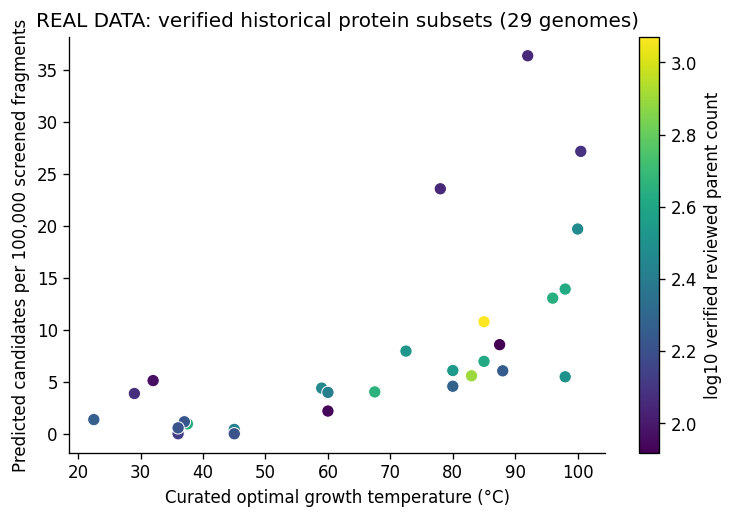

In [3]:
fig,ax=plt.subplots(figsize=(7.2,4.5))
rate=primary.amp_count/primary.n_screened*100000
sc=ax.scatter(primary.observed_temperature,rate,c=np.log10(primary.matched_source_proteins),
              cmap='viridis',s=55,edgecolors='white',linewidths=.6)
ax.set(xlabel='Curated optimal growth temperature (°C)',ylabel='Predicted candidates per 100,000 screened fragments',
       title=f'REAL DATA: verified historical protein subsets ({len(primary)} genomes)')
fig.colorbar(sc,ax=ax,label='log10 verified reviewed parent count')
save(fig,'observed_temperature_density');plt.show()

## Genuine ancestry adjustment and posterior diagnostics

The archaeal 53-marker tree comes from GTDB r226. Tips are exact versioned
assembly matches; pruning preserves patristic path lengths. A subsequent root
audit below corrects the original rooting description and tests full published
roots as well as the original induced-MRCA root. The covariance uses shared
root-to-common-ancestor branch length, scaled to correlations. It was not inferred
from the AMP outcome.

The NB2 model uses a screened-fragment offset, temperature per 10°C, full-proteome
size, reviewed fraction, and a Brownian phylogenetic random effect. The adjusted
model adds three PCs of screened-protein amino-acid composition on the **same 29
genomes**. Composition can be a real mediator of thermoadaptation as well as a
shared predictor input; comparing coefficients does not establish causal mediation.

Four chains retain 4,000 draws each after 3,000 tuning iterations at target_accept
.995. The final runs must have all-parameter Rhat <1.01, bulk ESS >=400 and zero
divergences. Earlier failed sampling attempts remain in the audit. Full draws
stay local; this notebook reads the checked, real fit summaries. Refit commands
are in `study/temperature/README.md` and use no simulated fallback.

In [4]:
from genomespot_lens.amp_study import tree_covariance, build_phylogenetic_nb
spec=importlib.util.spec_from_file_location('real_temperature_models',ROOT/'scripts/analyze_temperature_study.py')
module=importlib.util.module_from_spec(spec);spec.loader.exec_module(module)
X,design_info=module.design(primary.reset_index(drop=True),'observed_temperature',True)
C=tree_covariance(DATA/'phylogeny.nwk',primary.genome_id.tolist())
actual_model=build_phylogenetic_nb(primary.reset_index(drop=True),X,C)
assert np.isfinite(actual_model.compile_logp()(actual_model.initial_point()))
print('Built actual model:',len(primary),'genomes;',X.shape[1],'fixed effects')
print('Composition PC variance fractions:',design_info['aa_pca_variance_fraction'])
results=pd.DataFrame(json.loads((DATA/'posterior-results/results.json').read_text()))
assert results.status.eq('diagnostics_pass').all()
assert results.max_rhat.lt(1.01).all() and results.minimum_bulk_ess.ge(400).all()
assert results.divergences.eq(0).all()
display(results[['model','genomes','rr_per10C_median','rr_q025','rr_q975','max_rhat','minimum_bulk_ess','divergences']])

WARNING (pytensor.tensor.blas): Using NumPy C-API based implementation for BLAS functions.


Built actual model: 29 genomes; 7 fixed effects
Composition PC variance fractions: [0.46136420741906736, 0.2682073547306291, 0.12242378025292902]


,model,genomes,rr_per10C_median,rr_q025,rr_q975,max_rhat,minimum_bulk_ess,divergences
0,baseline,29,1.344444,1.050206,1.692028,1.001457,1441.361732,0
1,adjusted,29,1.171304,0.772833,1.733558,1.001525,2455.811615,0
2,parents100,26,1.263273,0.804723,1.919759,1.000827,2755.115980,0
3,broad,53,1.208891,0.912175,1.630001,1.002098,1850.949235,0
4,predicted,26,1.035088,0.565586,1.966718,1.002148,2689.909679,0


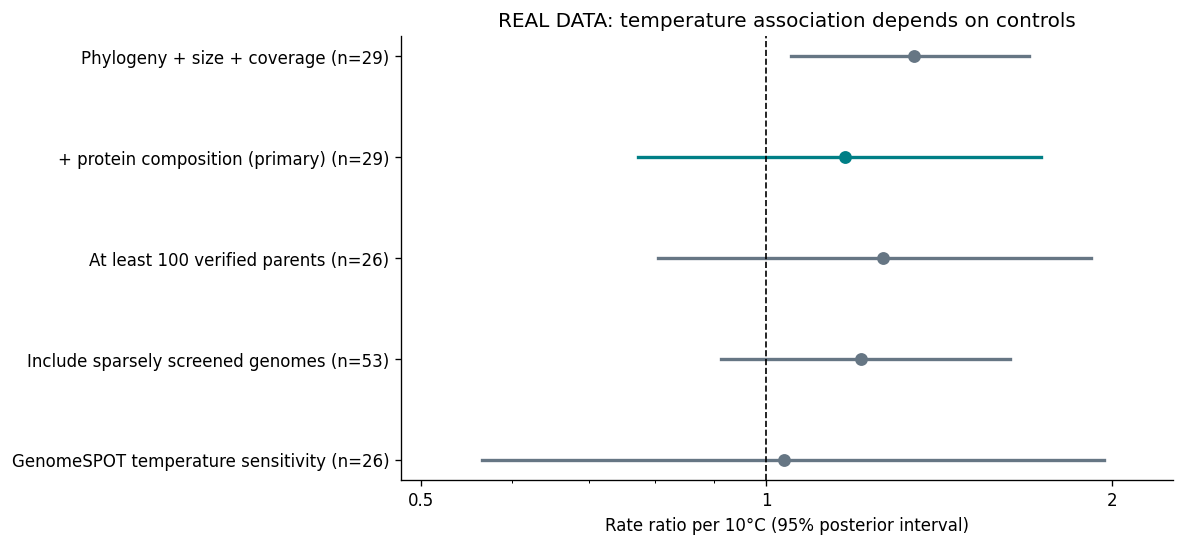

In [5]:
labels={'baseline':'Phylogeny + size + coverage', 'adjusted':'+ protein composition (primary)',
        'parents100':'At least 100 verified parents','broad':'Include sparsely screened genomes',
        'predicted':'GenomeSPOT temperature sensitivity'}
fig,ax=plt.subplots(figsize=(8.3,4.8))
for i,r in results.iterrows():
    color='#007f86' if r['model']=='adjusted' else '#667684'
    ax.plot([r.rr_q025,r.rr_q975],[i,i],color=color,lw=2)
    ax.scatter(r.rr_per10C_median,i,color=color,s=45,zorder=3)
ax.axvline(1,color='black',linestyle='--',lw=1)
ax.set_yticks(range(len(results)),[f'{labels[r.model]} (n={r.genomes})' for r in results.itertuples()])
ax.invert_yaxis();ax.set_xscale('log');ax.set_xticks([.5,1,2],['0.5','1','2'])
ax.xaxis.set_minor_formatter(NullFormatter())
ax.set_xlim(results.rr_q025.min()*.85,results.rr_q975.max()*1.15)
ax.set(xlabel='Rate ratio per 10°C (95% posterior interval)',title='REAL DATA: temperature association depends on controls')
save(fig,'phylogenetic_temperature_effects');plt.show()

## Exploratory prior and updated-tree sensitivity

An addendum was frozen after seeing the pilot, before fitting these checks
(commit 07a490c). The same 29 genomes have exact versioned tips in GTDB r232.
We vary non-intercept coefficient prior SD from 1.5 to 0.75 and 3, retaining all
other original priors, or update the tree from r226 to r232. These are limited
sensitivity checks, not an exhaustive prior/phylogeny validation. All use four
chains with the original final sampling settings and diagnostic gates.

In [6]:
sensitivity=pd.DataFrame(json.loads((DATA/'sensitivity-results/results.json').read_text()))
assert sensitivity.status.eq('diagnostics_pass').all()
assert sensitivity.max_rhat.lt(1.01).all() and sensitivity.minimum_bulk_ess.ge(400).all()
assert sensitivity.divergences.eq(0).all()
assert sensitivity.genomes.eq(len(primary)).all()
display(sensitivity[['model','genomes','non_intercept_prior_sd','rr_per10C_median',
                     'rr_q025','rr_q975','max_rhat','minimum_bulk_ess','divergences']])
print('Every tested adjusted interval spans 1; this is uncertainty, not evidence of equivalence.')

,model,genomes,non_intercept_prior_sd,rr_per10C_median,rr_q025,rr_q975,max_rhat,minimum_bulk_ess,divergences
0,prior075,29,0.75,1.209520,0.845911,1.728800,1.000988,2236.469133,0
1,prior300,29,3.00,1.149711,0.740671,1.744149,1.002043,3131.097817,0
2,tree232,29,1.50,1.163072,0.749933,1.741463,1.001703,2634.205491,0


Every tested adjusted interval spans 1; this is uncertainty, not evidence of equivalence.


### Rooting audit and two additional fits

The original pruning routine collapses a unary root path and resets its branch
to zero. It preserves pairwise distances and published clade orientation, but
the covariance root becomes the retained MRCA. This corrects the earlier prose
that the full published root was unchanged. The removed shared stems are 0.04572
(r226) and 0.14953935 (r232) substitutions/site. The root-audit addendum (b089cb9)
was committed before these two additional fits.

The new trees preserve the full published root, shared unary stem, root-to-tip
and root-to-MRCA depths, verified against the originals. These results are added
to the audit; the original fits are not silently replaced. All six adjusted
specifications below use the same 29 genomes and retain the original sampling
settings. They test a limited set of priors/root choices, not every plausible
model of evolution.

,model,genomes,shared_stem_substitutions_per_site,rr_per10C_median,rr_q025,rr_q975,max_rhat,minimum_bulk_ess,divergences
0,r226_published_root,29,0.045720,1.164643,0.760148,1.736538,1.001286,2283.428999,0
1,r232_published_root,29,0.149539,1.162036,0.771923,1.723838,1.000719,2924.552030,0


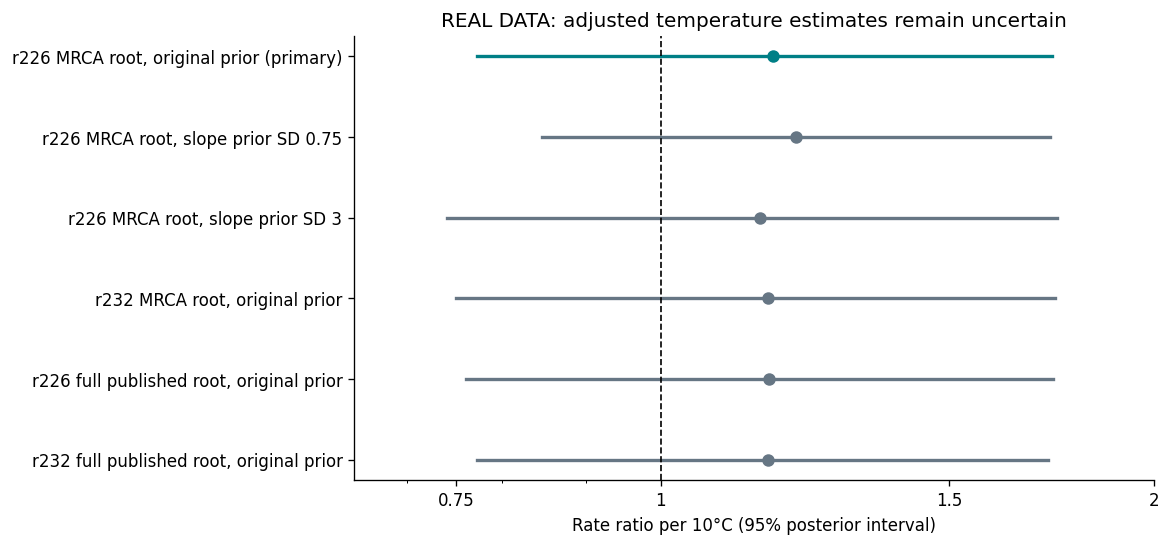

In [7]:
rooting=pd.DataFrame(json.loads((DATA/'rooting-results/results.json').read_text()))
assert rooting.status.eq('diagnostics_pass').all()
assert rooting.max_rhat.lt(1.01).all() and rooting.minimum_bulk_ess.ge(400).all()
assert rooting.divergences.eq(0).all()
display(rooting[['model','genomes','shared_stem_substitutions_per_site','rr_per10C_median',
                'rr_q025','rr_q975','max_rhat','minimum_bulk_ess','divergences']])
combined=pd.concat([results[results.model=='adjusted'],sensitivity,rooting],ignore_index=True)
names={'adjusted':'r226 MRCA root, original prior (primary)',
       'prior075':'r226 MRCA root, slope prior SD 0.75',
       'prior300':'r226 MRCA root, slope prior SD 3',
       'tree232':'r232 MRCA root, original prior',
       'r226_published_root':'r226 full published root, original prior',
       'r232_published_root':'r232 full published root, original prior'}
fig,ax=plt.subplots(figsize=(8.6,4.8))
for i,r in combined.iterrows():
    color='#007f86' if r['model']=='adjusted' else '#667684'
    ax.plot([r.rr_q025,r.rr_q975],[i,i],color=color,lw=2)
    ax.scatter(r.rr_per10C_median,i,color=color,s=42,zorder=3)
ax.axvline(1,color='black',ls='--',lw=1)
ax.set_yticks(range(len(combined)),[names[x] for x in combined.model]);ax.invert_yaxis()
ax.set_xscale('log');ax.set_xticks([.75,1,1.5,2],['0.75','1','1.5','2'])
ax.xaxis.set_minor_formatter(NullFormatter());ax.set_xlim(.65,2)
ax.set(xlabel='Rate ratio per 10°C (95% posterior interval)',
       title='REAL DATA: adjusted temperature estimates remain uncertain')
save(fig,'temperature_prior_root_sensitivity');plt.show()

## Within-homology sensitivity — a separate analysis

MMseqs2 groups use 30% or 50% identity with 80% bidirectional coverage; these are
homologous groups, not proven orthologs. Retain groups represented in >=5 primary
genomes. Groups with zero total candidates cannot inform a conditional family
contrast and are reported separately. The per-parent endpoint differs from the
genome-wide union: a fragment occurring in two different parent sequences can
contribute to both parent outcomes.

Quasi-Poisson models use exact parent-fragment exposure, homology-group fixed
effects, parent length and, in the adjusted variant, three parent-composition PCs.
Two-way cluster-robust uncertainty uses genome and homology groups. This is
**not** another phylogenetic mixed model. Report both clustering definitions and
their intervals; secondary p-values are exploratory and not discovery claims.

In [8]:
homology=pd.read_csv(DATA/'homology-results/effects.csv')
display(homology[['identity_cutoff','composition_adjusted','genomes','parent_rows',
                 'informative_homology_groups','rr_per10C','rr_q025','rr_q975',
                 'pvalue','pearson_dispersion']])

,identity_cutoff,composition_adjusted,genomes,parent_rows,informative_homology_groups,rr_per10C,rr_q025,rr_q975,pvalue,pearson_dispersion
0,30,False,29,2021,159,1.347652,1.129321,1.608191,0.001759,10.335900
1,30,True,29,2021,159,1.234097,1.036735,1.469031,0.019758,10.354443
2,50,False,29,774,85,1.186814,0.980027,1.437232,0.077526,8.821776
3,50,True,29,774,85,1.162779,0.983121,1.375269,0.076295,7.942280


## GenomeSPOT agreement is not independent validation

The following comparison uses the primary cohort's unflagged temperature subset.
Published GenomeSPOT accession lists are checked for overlap; these lists omit
assembly versions, so the check conservatively flags shared accession bases.
This audit is never used to relax the exact-version phenotype/source join.
The final GenomeSPOT models use original training and holdout data, so agreement
with these strains must not be called out-of-sample model validation.

In [9]:
agreement=json.loads((DATA/'temperature-agreement.json').read_text())
display(pd.Series(agreement).drop('holdout_file_sha256'))

genomes                                                                                       26
mae_celsius                                                                             5.598862
pearson_correlation                                                                     0.961163
listed_training_or_original_holdout_overlap                                                    2
interpretation                                 Label agreement only, NOT independent predicti...
dtype: object

## Interpretation and next decisive work

The composition-adjusted primary interval spans no association. This small pilot
does not establish a temperature effect independent of composition and ancestry;
it also does not prove such an effect is absent. Within-homology results depend
on the clustering definition. Candidate counts describe the historical reviewed
protein subset and predicted activity, not a complete proteome screen or measured
antimicrobial function.

The proposed contribution is an auditable comparative test, not a claim that hot
microbes or ecological AMP discovery are new. The prior/tree checks above leave the pilot conclusion unchanged. The separate
real-data bacterial comparison in notebook 06 tests species/habitat confounding
with a different AMP endpoint; it is not temperature replication. Next decisive
work is an independent uniform screen/replication cohort and a powered design.
The ATB resistance question still needs its full screened-sample/parent/score
export and resolution of its conflicting threshold descriptions. Carbon-A's
documented eukaryotic CDS task does not replace prokaryotic annotations here.

Sources: [archaeome](https://doi.org/10.1038/s41564-025-02061-0),
[TEMPURA](https://doi.org/10.1264/jsme2.ME20074),
[GTDB r226](https://data.gtdb.ecogenomic.org/releases/release226/226.0/),
[GenomeSPOT](https://github.com/cultivarium/GenomeSPOT).
Data licenses are separate from the software license; see the source notices.